# 06 · Distributions, binomial model, expectation and variance

Distribution of the proliferation score and the other numeric variables, a normal check, a binomial model for ER-negative status, and expectation and variance by group.

**Input:** `analysis_table.csv` (rows with `in_cohort`)  
**Output:** figures `06_*`

Variances and standard deviations use divisor *n* (the variance of the empirical distribution), so decompositions below are exact.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def find_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "notebooks").is_dir() and (folder / "data" / "processed" / "analysis_table.csv").is_file():
            return folder.resolve()
    raise FileNotFoundError("Project root not found (needs notebooks/ and data/processed/analysis_table.csv; run notebook 04 first).")

ROOT = find_project_root()
PROC, FIG = ROOT / "data" / "processed", ROOT / "figures" / "phase2"
FIG.mkdir(parents=True, exist_ok=True)

# One colour per meaning in every figure: blue = clinical / positive, orange = molecular / negative, grey = neutral.
POS, NEG, GREY = "#2F6DB5", "#D9822B", "#6B7280"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10,
})

def save_fig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

df = pd.read_csv(PROC / "analysis_table.csv")
co = df[df["in_cohort"]].copy().reset_index(drop=True)
PROLIF = "prolif_score"
print("Analytic cohort:", len(co), "patients")

VARS = {PROLIF: "Proliferation score", "luminal_score": "Luminal score",
        "ERBB2": "ERBB2, log2(TPM+1)", "age": "Age (years)"}
ER_COLOR = {"Positive": POS, "Negative": NEG}

Analytic cohort: 940 patients


## 1. Distribution of the numeric variables

Mean, variance and shape of each variable, with potential outliers by the 1.5 × IQR rule. Potential outliers are retained.

In [21]:
rows = []
for v, lab in VARS.items():
    x = co[v].astype(float)
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    rows.append({"variable": lab, "n": x.size, "mean": x.mean(), "variance": x.var(ddof=0), "SD": x.std(ddof=0),
                 "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x),
                 "min": x.min(), "Q1": q1, "median": x.median(), "Q3": q3, "max": x.max(),
                 "outliers (1.5 × IQR)": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())})
display(pd.DataFrame(rows).set_index("variable").round(2))

,n,mean,variance,SD,skewness,excess kurtosis,min,Q1,median,Q3,max,outliers (1.5 × IQR)
variable,,,,,,,,,,,,
Proliferation score,940,4.59,1.17,1.08,-0.18,-0.34,1.39,3.84,4.64,5.37,7.34,1
Luminal score,940,-0.01,0.77,0.88,-0.99,-0.20,-2.39,-0.40,0.29,0.63,1.34,25
"ERBB2, log2(TPM+1)",940,7.07,2.38,1.54,0.88,1.90,1.73,6.21,6.96,7.61,12.53,86
Age (years),940,58.67,171.95,13.11,0.16,-0.52,26.00,49.00,59.00,68.00,89.00,0


The proliferation score is close to symmetric (skewness −0.18) with one outlier. The luminal score is left-skewed (−0.99, 25 outliers) and *ERBB2* right-skewed (0.88, excess kurtosis 1.90, 86 outliers). The extreme values lie in the low-luminal and high-*ERBB2* tails seen below; no data error was found in notebook 03, so they are retained.

## 2. Normal check

A normal model *N(μ, σ²)* with the sample mean and SD is compared with the histogram and a normal Q-Q plot (standardised values against normal quantiles; points on the diagonal mean agreement). The cohort mixes ER-positive and ER-negative patients, so the check is repeated within each group. The share of values within 1, 2 and 3 SD is compared with the normal values.

saved figures\phase2\06_prolif_normal_check.png


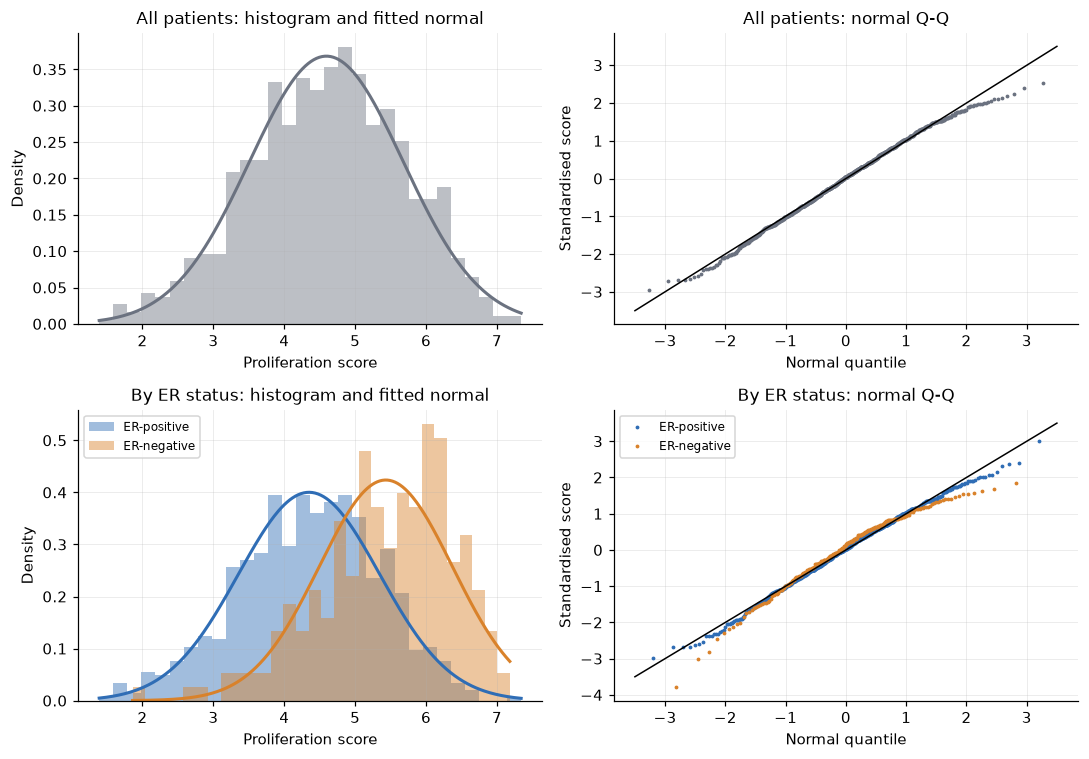

,All,ER-positive,ER-negative,normal
within 1 SD,0.662,0.672,0.698,0.683
within 2 SD,0.961,0.956,0.958,0.954
within 3 SD,1.000,0.999,0.991,0.997


In [22]:
def qq(ax, x, color, label):
    x = np.sort(np.asarray(x, float)); n = x.size
    theo = stats.norm.ppf((np.arange(1, n + 1) - 0.5) / n)
    ax.plot(theo, (x - x.mean()) / x.std(ddof=0), ".", ms=3, color=color, label=label)

def hist_normal(ax, x, color, label=None, bins=30):
    x = np.asarray(x, float)
    ax.hist(x, bins=bins, density=True, color=color, alpha=0.45, label=label)
    g = np.linspace(x.min(), x.max(), 300)
    ax.plot(g, stats.norm.pdf(g, x.mean(), x.std(ddof=0)), color=color, lw=2)

x = co[PROLIF]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
hist_normal(axes[0, 0], x, GREY); axes[0, 0].set_title("All patients: histogram and fitted normal")
qq(axes[0, 1], x, GREY, "All"); axes[0, 1].set_title("All patients: normal Q-Q")
for s, c in ER_COLOR.items():
    hist_normal(axes[1, 0], co.loc[co["ER"] == s, PROLIF], c, f"ER-{s.lower()}")
    qq(axes[1, 1], co.loc[co["ER"] == s, PROLIF], c, f"ER-{s.lower()}")
axes[1, 0].set_title("By ER status: histogram and fitted normal"); axes[1, 0].legend(fontsize=8)
axes[1, 1].set_title("By ER status: normal Q-Q"); axes[1, 1].legend(fontsize=8)
for ax in axes[:, 0]: ax.set_xlabel("Proliferation score"); ax.set_ylabel("Density")
for ax in axes[:, 1]:
    ax.plot([-3.5, 3.5], [-3.5, 3.5], color="black", lw=1); ax.set_xlabel("Normal quantile"); ax.set_ylabel("Standardised score")
fig.tight_layout(); save_fig(fig, "06_prolif_normal_check"); plt.show()

def within_k(x, k):
    x = np.asarray(x, float); return np.mean(np.abs(x - x.mean()) <= k * x.std(ddof=0))
emp = {"All": x, "ER-positive": co.loc[co["ER"] == "Positive", PROLIF], "ER-negative": co.loc[co["ER"] == "Negative", PROLIF]}
tab = pd.DataFrame({name: [within_k(v, k) for k in (1, 2, 3)] for name, v in emp.items()}, index=["within 1 SD", "within 2 SD", "within 3 SD"])
tab["normal"] = [stats.norm.cdf(k) - stats.norm.cdf(-k) for k in (1, 2, 3)]
display(tab.round(3))

A normal model describes the proliferation score reasonably well: 66%, 96% and 100% of values lie within 1, 2 and 3 SD (normal: 68%, 95%, 99.7%), and the Q-Q plot follows the diagonal with slightly light tails. Within the ER-negative group the upper tail is compressed (points below the line). The overall distribution is a mixture of two groups with different means (4.35 and 5.43) but similar spread, and remains close to normal because the groups overlap. The normal model is adequate as a description of the score.

The same check for the luminal score and *ERBB2* expression.

saved figures\phase2\06_molecular_normal_check.png


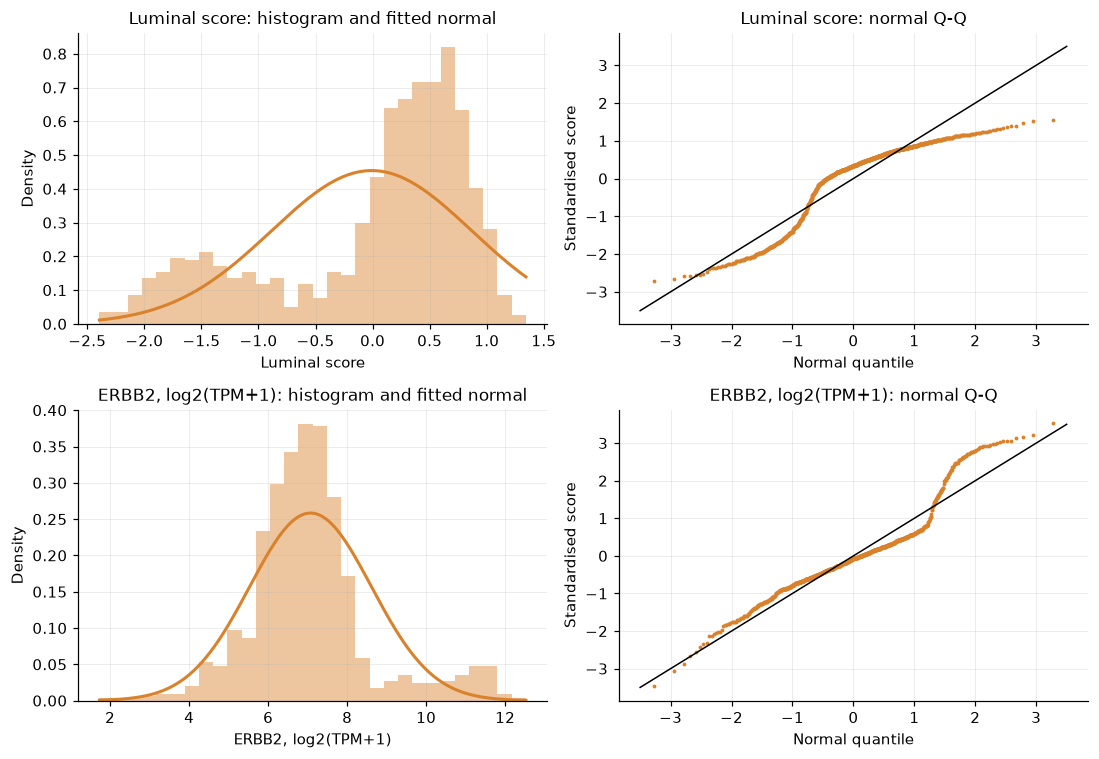

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, (v, lab) in enumerate([("luminal_score", VARS["luminal_score"]), ("ERBB2", VARS["ERBB2"])]):
    hist_normal(axes[i, 0], co[v], NEG); axes[i, 0].set_xlabel(lab); axes[i, 0].set_ylabel("Density")
    axes[i, 0].set_title(f"{lab}: histogram and fitted normal")
    qq(axes[i, 1], co[v], NEG, lab); axes[i, 1].plot([-3.5, 3.5], [-3.5, 3.5], color="black", lw=1)
    axes[i, 1].set_xlabel("Normal quantile"); axes[i, 1].set_ylabel("Standardised score"); axes[i, 1].set_title(f"{lab}: normal Q-Q")
fig.tight_layout(); save_fig(fig, "06_molecular_normal_check"); plt.show()

The normal model does not fit the luminal score (a main cluster and a separate low-luminal group) or *ERBB2* (a long right tail from a small group of very high values, giving an S-shaped Q-Q plot). The mean and SD alone would misdescribe these two variables.

## 3. Expectation and variance by group

For an indicator *I* of an event with probability *p*, *E[I] = p* and *Var(I) = p(1 − p)*.

For the proliferation score *X* and a grouping *G*, the laws of total expectation and variance are

*E[X] = Σ p_g E[X | g]*  
*Var(X) = Σ p_g Var(X | g) + Σ p_g (E[X | g] − E[X])²*

The first term of the variance is the variability within groups, the second the variability between group means. Their ratio is the share of the variance of *X* that the grouping accounts for. Groupings with more groups absorb more variance by construction, so only groupings with the same number of groups are compared. The ER × luminal grouping has a cell of only 6 patients, so its share is less stable; the smallest cell is reported alongside each share.

In [24]:
er_neg = co["ER"].eq("Negative")
print(f"ER-negative indicator: E = {er_neg.mean():.4f}, p(1-p) = {er_neg.mean() * (1 - er_neg.mean()):.4f}, Var = {er_neg.var(ddof=0):.4f}")

cutm = {v: co[v].median() for v in ["luminal_score", "ERBB2"]}
lum = np.where(co["luminal_score"] > cutm["luminal_score"], "High luminal", "Low luminal")
erb = np.where(co["ERBB2"] > cutm["ERBB2"], "High ERBB2", "Low ERBB2")
G = {"ER": co["ER"], "HER2": co["HER2"], "ER x HER2": co["ER"] + "/" + co["HER2"],
     "Luminal group": pd.Series(lum), "ERBB2 group": pd.Series(erb), "ER x Luminal group": co["ER"] + "/" + pd.Series(lum)}

def total_variance(x, g):
    d = pd.DataFrame({"x": np.asarray(x, float), "g": np.asarray(g)})
    gb = d.groupby("g")["x"]
    p, m, v = gb.size() / len(d), gb.mean(), gb.var(ddof=0)
    within, between, total = (p * v).sum(), (p * (m - d["x"].mean()) ** 2).sum(), d["x"].var(ddof=0)
    assert np.isclose(within + between, total) and np.isclose((p * m).sum(), d["x"].mean())
    return {"groups": len(p), "smallest cell": int(gb.size().min()), "within": within, "between": between,
            "total": total, "between / total": between / total}

display(pd.DataFrame.from_dict({k: total_variance(co[PROLIF], g) for k, g in G.items()}, orient="index").round(3))

print("\nMean and variance of the proliferation score by ER status:")
display(co.groupby("ER")[PROLIF].agg(patients="size", mean="mean", variance=lambda s: s.var(ddof=0)).round(3))

ER-negative indicator: E = 0.2255, p(1-p) = 0.1747, Var = 0.1747


,groups,smallest cell,within,between,total,between / total
ER,2,212,0.970,0.205,1.174,0.174
HER2,2,182,1.161,0.014,1.174,0.012
ER x HER2,4,42,0.935,0.239,1.174,0.204
Luminal group,2,470,1.072,0.102,1.174,0.087
ERBB2 group,2,470,1.139,0.036,1.174,0.030
ER x Luminal group,4,6,0.951,0.223,1.174,0.190



Mean and variance of the proliferation score by ER status:


,patients,mean,variance
ER,,,
Negative,212,5.432,0.886
Positive,728,4.350,0.994


The mean of *X* (4.59) is the expected proliferation score of a randomly chosen patient, and the variance (1.17) its average squared deviation from that mean. ER-negative patients have a higher mean than ER-positive patients (5.43 vs 4.35) with similar variances (0.89 vs 0.99). ER status accounts for 17.4% of the variance of *X* and HER2 for 1.2%; with four groups each, ER × HER2 accounts for 20.4% and ER × luminal group for 19.0%. The shares are descriptive and depend on the cut-offs.

## 4. Binomial model for ER-negative status

Let *Y* be the number of ER-negative patients among *n* = 20 patients, and *p* the cohort proportion of ER-negative patients. *Y ~ Binomial(n, p)* requires a fixed *n*, two outcomes, independent patients and the same *p* for every patient.

Two checks: (a) 20 patients drawn at random from the cohort, repeated 10,000 times, against the binomial probabilities (drawing without replacement from 940 patients is close to independent draws); (b) the ER-negative proportion by tissue source site against the binomial spread expected if *p* were the same everywhere.

p = 0.226; E[Y] = np = 4.51; Var(Y) = np(1-p) = 3.49; SD = 1.87
P(Y >= 8) = 0.0610
simulated: mean = 4.52, variance = 3.46


,site,n,k,proportion,z,outside 95% limits
9,BH,134,21,0.157,-1.906,False
1,A2,99,25,0.253,0.643,False
12,E2,86,22,0.256,0.672,False
3,A8,84,8,0.095,-2.857,True
11,D8,75,16,0.213,-0.253,False
7,AR,65,12,0.185,-0.789,False
6,AO,45,12,0.267,0.660,False
14,EW,42,11,0.262,0.564,False
2,A7,38,12,0.316,1.331,False
5,AN,38,12,0.316,1.331,False


19 sites with n >= 10; outside the 95% limits: 2 (expected about 1.0); mean z^2 = 1.77 (about 1 if p is constant)
saved figures\phase2\06_binomial_check.png


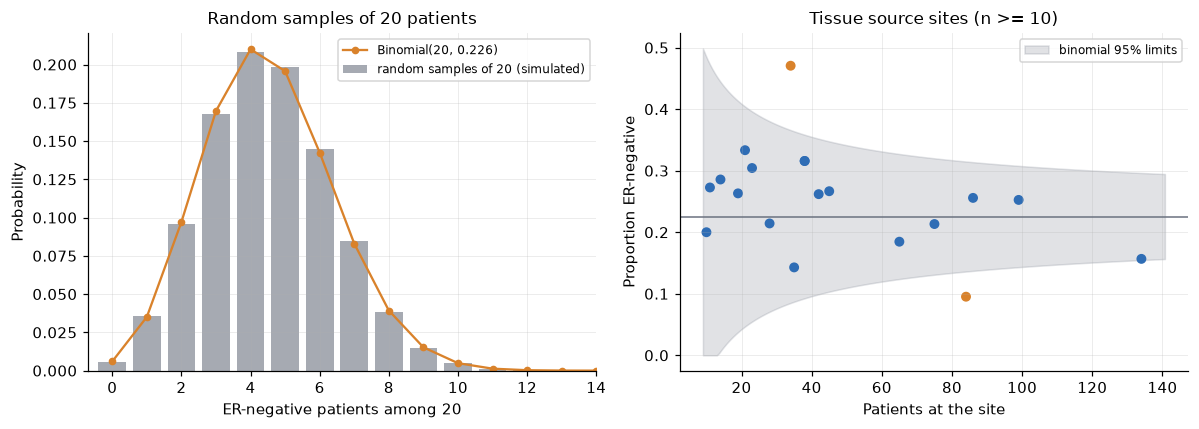

In [25]:
p = er_neg.mean(); n = 20
k = np.arange(n + 1); pmf = stats.binom.pmf(k, n, p)
print(f"p = {p:.3f}; E[Y] = np = {n * p:.2f}; Var(Y) = np(1-p) = {n * p * (1 - p):.2f}; SD = {np.sqrt(n * p * (1 - p)):.2f}")
print(f"P(Y >= 8) = {stats.binom.sf(7, n, p):.4f}")

rng = np.random.default_rng(2026)
sim = np.array([er_neg.to_numpy()[rng.choice(len(co), n, replace=False)].sum() for _ in range(10_000)])
print(f"simulated: mean = {sim.mean():.2f}, variance = {sim.var():.2f}")

# (b) site-level check
d = pd.DataFrame({"site": co["patient_submitter_id"].str.split("-").str[1], "neg": er_neg})
site = d.groupby("site")["neg"].agg(n="size", k="sum").query("n >= 10").reset_index()
site["proportion"] = site["k"] / site["n"]
site["z"] = (site["k"] - site["n"] * p) / np.sqrt(site["n"] * p * (1 - p))
site["outside 95% limits"] = site["z"].abs() > 1.96
display(site.sort_values("n", ascending=False).round(3))
print(f"{len(site)} sites with n >= 10; outside the 95% limits: {int(site['outside 95% limits'].sum())} (expected about {0.05 * len(site):.1f}); "
      f"mean z^2 = {np.mean(site['z'] ** 2):.2f} (about 1 if p is constant)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.bar(k, np.bincount(sim, minlength=n + 1) / len(sim), color=GREY, alpha=0.6, label="random samples of 20 (simulated)")
ax.plot(k, pmf, "o-", color=NEG, ms=4, label=f"Binomial(20, {p:.3f})")
ax.set_xlim(-0.7, 14); ax.set_xlabel("ER-negative patients among 20"); ax.set_ylabel("Probability"); ax.legend(fontsize=8)
ax.set_title("Random samples of 20 patients")
ax = axes[1]
g = np.linspace(site["n"].min() * 0.9, site["n"].max() * 1.05, 200)
ax.fill_between(g, np.clip(p - 1.96 * np.sqrt(p * (1 - p) / g), 0, 1), np.clip(p + 1.96 * np.sqrt(p * (1 - p) / g), 0, 1), color=GREY, alpha=0.2, label="binomial 95% limits")
ax.axhline(p, color=GREY, lw=1)
ax.scatter(site["n"], site["proportion"], c=np.where(site["outside 95% limits"], NEG, POS), s=30)
ax.set_xlabel("Patients at the site"); ax.set_ylabel("Proportion ER-negative"); ax.legend(fontsize=8)
ax.set_title("Tissue source sites (n >= 10)")
fig.tight_layout(); save_fig(fig, "06_binomial_check"); plt.show()

With *p* = 0.226, *Y* has mean 4.51 and variance 3.49. For random samples of 20 patients the binomial model fits well (simulated mean 4.52, variance 3.46). It does not hold for site-level counts: the mean z² is 1.77 rather than about 1, and two of the 19 sites lie outside the limits (orange; C8 with 47% ER-negative among 34 patients, A8 with 9.5% among 84). The ER-negative probability differs between sites, so *p* is not constant and counts within a site vary more than a binomial model allows. The limits use a normal approximation, which is rough for the smallest sites.